# IPO Listing Gain Prediction

**Notebook 4 of 5 - Model Training**

## Approach

1. Keep 2024 onwards aside as **test data** - all tuning on 2010-2023
2. Validation by year: train on all years before Y, predict Y (Y = 2019 ... 2023)
3. Baselines: overall median, and median of the same subscription bucket
4. Models: Ridge, Random Forest, LightGBM -> check train vs valid error (overfitting), then tune
5. Test on 2024-2026: once with a frozen model, once with walk-forward retraining
6. Predict an 80% range, and look at feature importance

## Metrics

| Metric | Why |
|---|---|
| **MAE** (main) | average error in percentage points, not dominated by a few 200% IPOs |
| Median AE | error on a typical IPO |
| R2 | share of variance explained (used in the train vs valid table) |
| **Spearman** | does the model **rank** IPOs correctly? - that's what an apply / skip decision needs |

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from useful_func import missing_info

# itertools -> all combinations for the grid, json -> save the best settings
import itertools
import json
# shap -> explain how much each feature pushed a prediction up or down
import shap
# models
from lightgbm import LGBMRegressor
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
# scores
from sklearn.metrics import r2_score, mean_absolute_error
# pipeline = fill missing -> (scale) -> model, all fitted on training data only
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_style("darkgrid")
pd.set_option("display.float_format", "{:.2f}".format)
fig_dir = "../reports/figures/"

D:\Ck\IMARTICUS\github\personal-projects\imarticus projects\ML\ipo-listing-predictor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# read dataset
# feature table from notebook 03
df = pd.read_csv("../data/processed/ipo_features.csv", parse_dates=["listing_date"])
df.shape

(634, 31)

In [3]:
# y -> listing day gain in %
target = "target_gain_pct"

# X -> 13 inputs the model can use (all known before listing)
base_features = ["log_sub_qib", "log_sub_hni", "log_sub_rii", "log_sub_total", "qib_to_rii",
                 "log_issue_size", "log_offer_price",
                 "nifty_ret_1m", "nifty_ret_3m", "nifty_vs_200dma", "vix", "recent_ipo_mean_gain", "recent_ipo_count"]
# 3 extra "line vs last year" features, tried as a second option during tuning
relative = ["sub_total_vs_recent", "sub_qib_vs_recent", "sub_hni_vs_recent"]
feature_sets = {"base": base_features, "with_relative": base_features + relative}

missing_info(df[base_features + relative + [target]])

,column_name,num_missing,missing%
0,recent_ipo_mean_gain,12,1.89
1,sub_total_vs_recent,10,1.58
2,sub_qib_vs_recent,10,1.58
3,sub_hni_vs_recent,10,1.58


In [4]:
# split data by time - 2010-2023 for training / tuning, 2024 onwards for testing
# (not train_test_split, a random split would train on 2025 and test on 2019 = using the future)
dev = df[df["year"] < 2024].reset_index(drop=True)
test = df[df["year"] >= 2024].reset_index(drop=True)

print(f"Shape of dev (2010-2023) -: {dev.shape}")
print(f"Shape of test (2024-2026) -: {test.shape}")

Shape of dev (2010-2023) -: (432, 31)
Shape of test (2024-2026) -: (202, 31)


## Step 1: Validation Strategy - Year Folds

**Why not `regression_eval` / KFold from useful_func?** `regression_eval` uses `KFold(shuffle=True)`. For this
data that would train on 2023 IPOs and predict 2019 IPOs - using the future to predict the past, so the score
would look better than it really is.

**What we do instead:** the same idea with **year folds** - train on all IPOs before year Y, validate on Y.

**Extra gap:** market features look 7 days back, so the last 7 days of the previous year are also left out of
training - otherwise an IPO on 3 Jan could be scored by a model that has seen one from 30 Dec.

In [5]:
# 5 practice tests, one per year 2019 to 2023
# train = every IPO before (1 Jan of that year - 7 days), valid = IPOs of that year
# the 7 day gap is because market features look 7 days back
# yield -> gives one (train rows, valid rows) pair at a time
def year_folds(d):
    for year in range(2019, 2024):
        cutoff = pd.Timestamp(year, 1, 1) - pd.Timedelta(days=7)
        yield d.index[d["listing_date"] < cutoff], d.index[d["year"] == year]


# size of each fold
for tr, va in year_folds(dev):
    print(dev.loc[va, "year"].iloc[0], " train -:", len(tr), " valid -:", len(va))

2019  train -: 240  valid -: 16
2020  train -: 255  valid -: 15
2021  train -: 271  valid -: 63
2022  train -: 331  valid -: 39
2023  train -: 371  valid -: 59


## Step 2: Baselines

**What we do:** 2 simple models with no ML:
1. **Median baseline** - predict the median gain of all past IPOs
2. **Bucket median** - median gain of past IPOs in the same total subscription bucket
   (<1x, 1-3x, 3-10x, 10-30x, 30-100x, 100x+)

**Why we do it:** The bucket median is more or less what an experienced IPO investor does by eye. If the ML
models can't clearly beat it, they're not worth using.

In [6]:
# baseline 1 -> always guess the median gain of the training IPOs
# fit / predict like a sklearn model, so the same code can train it
class MedianModel:
    def fit(self, X, y):
        self.m = float(np.median(y))
        return self

    def predict(self, X):
        # same number for every IPO
        return np.full(len(X), self.m)


# baseline 2 -> guess the median gain of past IPOs in the same subscription group
# this is what an experienced investor does by eye, ML has to beat this
class BucketMedian:
    edges = [0, 1, 3, 10, 30, 100, np.inf]

    def fit(self, X, y):
        # group number 0..5 for every IPO
        bucket = pd.cut(X["sub_total"], self.edges, right=False, labels=False)
        y = pd.Series(np.asarray(y, dtype=float), index=X.index)
        # overall median is used if a group had no IPOs in training
        self.overall = float(y.median())
        # {group number: median gain}
        self.medians = y.groupby(bucket).median().to_dict()
        return self

    def predict(self, X):
        bucket = pd.cut(X["sub_total"], self.edges, right=False, labels=False)
        return np.array([self.medians.get(b, self.overall) for b in bucket], dtype=float)

## Step 3: Models

| Model | Why try it |
|---|---|
| Ridge | linear, regularisation handles the correlated subscription columns |
| Random Forest | non-linear, robust to outliers, not much tuning needed |
| LightGBM | gradient boosting, usually the strongest on tabular data |

**Data options** tried for each model:
- features: `base` (13 features) vs `with_relative` (+3 relative subscription features)
- recency weights: none vs half-life of 4 years (older years count less)

NaNs are filled with the median inside a pipeline (`SimpleImputer`), so the median comes from the training fold
only.

In [7]:
# build a model from its name and settings (p)
def make_model(name, p):
    if name == "median":
        return MedianModel()
    if name == "bucket_median":
        return BucketMedian()
    # ridge = straight line model, needs scaled inputs, alpha = how much it is held back
    if name == "ridge":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=p["alpha"]))
    # random forest = 400 trees that vote, max_features=0.5 -> each split looks at half the columns
    if name == "random_forest":
        rf = RandomForestRegressor(n_estimators=400, max_depth=p["max_depth"], min_samples_leaf=p["min_samples_leaf"],
                                   max_features=0.5, random_state=42, n_jobs=-1)
        return make_pipeline(SimpleImputer(strategy="median"), rf)
    # lightgbm = trees built one after another, each fixes the mistakes of the last ones
    # it can handle NaN by itself, so no imputer
    if name == "lightgbm":
        return LGBMRegressor(learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                             random_state=42, verbose=-1, **p)


# which columns a model gets
def columns(name, data):
    if name == "bucket_median":
        return ["sub_total"]
    if name == "median":
        return base_features
    return feature_sets[data["features"]]


# fit a model on a training frame
# data["half_life"] -> optional: give old years less weight (4 = a year 4 years older counts half)
def train(name, p, data, frame):
    cols = columns(name, data)
    model = make_model(name, p)
    hl = data.get("half_life")
    if hl is None:
        return model.fit(frame[cols], frame[target])
    w = 0.5 ** ((frame["year"].max() - frame["year"].to_numpy()) / hl)
    # inside a pipeline the weight has to be passed as "<step name>__sample_weight"
    if hasattr(model, "steps"):
        return model.fit(frame[cols], frame[target], **{model.steps[-1][0] + "__sample_weight": w})
    return model.fit(frame[cols], frame[target], sample_weight=w)

### Step 3.1: First Try - Train vs Valid Error

**What we do:** `time_eval` - same idea as `regression_eval` from useful_func (train vs valid MAE and R2 in one
`result_reg_df` table), but with the year folds. First run: baselines and models with default-ish settings.

**Why we do it:** A big gap between train and valid error means the model is memorising the training data
(overfitting) - better to see that before tuning.

In [8]:
# same idea as regression_eval from class, but with year folds instead of shuffled KFold
# adds one row to result_reg_df -> average train MAE / valid MAE / train R2 / valid R2 over the 5 folds
# train much better than valid = overfitting
def time_eval(method, name, p, data, result_reg_df=None):
    if result_reg_df is None:
        result_reg_df = pd.DataFrame({"method": [], "train_mae": [], "valid_mae": [], "train_r2": [], "valid_r2": []})

    cols = columns(name, data)
    train_mae_list, valid_mae_list = [], []
    train_r2_list, valid_r2_list = [], []
    for tr, va in year_folds(dev):
        # fit on the past, predict both the past (train) and the next year (valid)
        model = train(name, p, data, dev.loc[tr])
        y_train_pred = model.predict(dev.loc[tr, cols])
        y_valid_pred = model.predict(dev.loc[va, cols])

        train_mae_list.append(mean_absolute_error(dev.loc[tr, target], y_train_pred))
        valid_mae_list.append(mean_absolute_error(dev.loc[va, target], y_valid_pred))
        train_r2_list.append(r2_score(dev.loc[tr, target], y_train_pred))
        valid_r2_list.append(r2_score(dev.loc[va, target], y_valid_pred))

    # new row at the end of the table
    result_reg_df.loc[len(result_reg_df)] = [method, np.mean(train_mae_list), np.mean(valid_mae_list),
                                             np.mean(train_r2_list), np.mean(valid_r2_list)]
    return result_reg_df

In [9]:
# first try - baselines and models with default-ish settings
base = {"features": "base", "half_life": None}

result_reg_df = time_eval("median baseline", "median", {}, {})
result_reg_df = time_eval("bucket median baseline", "bucket_median", {}, {}, result_reg_df)
result_reg_df = time_eval("ridge alpha=1", "ridge", {"alpha": 1}, base, result_reg_df)
# no depth limit -> trees can grow until every leaf has 1 IPO (can memorise)
result_reg_df = time_eval("rf max_depth=None, min_leaf=1", "random_forest",
                          {"max_depth": None, "min_samples_leaf": 1}, base, result_reg_df)
result_reg_df = time_eval("lgbm 500 trees, 31 leaves", "lightgbm",
                          {"n_estimators": 500, "num_leaves": 31, "min_child_samples": 20, "objective": "l2"},
                          base, result_reg_df)
result_reg_df

,method,train_mae,valid_mae,train_r2,valid_r2
0,median baseline,16.06,27.26,-0.10,-0.34
1,bucket median baseline,10.23,16.26,0.55,0.51
2,ridge alpha=1,11.80,18.50,0.53,0.38
3,"rf max_depth=None, min_leaf=1",3.70,14.88,0.94,0.56
4,"lgbm 500 trees, 31 leaves",3.85,15.85,0.92,0.50


**Observations:**
- Random Forest with no depth limit and LightGBM with 31 leaves fit the training years almost perfectly
  (train MAE **~4** vs valid **~15**) - a big train-valid gap
- for a random forest a big gap is normal - each tree memorises its own bootstrap sample and the averaging is
  what generalises - so the **valid MAE** is what really matters
- interesting: the unlimited forest is actually slightly better on validation here (**14.9**)

**Next:** tuning tries limiting the trees (depth 4 / 8, min 5 / 15 samples per leaf).

## Step 4: Hyperparameter Tuning

**What we do:** Small grid for each model x 4 data options, scored with year folds. Pick the setting with the
lowest MAE over 2019-2023.

| Model | Grid |
|---|---|
| Ridge | alpha: 0.3, 3, 30 |
| Random Forest | max_depth: 4, 8 - min_samples_leaf: 5, 15 (400 trees, max_features 0.5) |
| LightGBM | n_estimators: 200, 500 - num_leaves: 7, 15 - min_child_samples: 10, 25 - objective: l2, huber (learning rate 0.03) |
| Data options | features: base / with_relative - half-life: none / 4 years |

**94 combinations** in total.

In [10]:
# all the scores in one dict
# mae = average miss, median_ae = miss on a typical IPO, rmse = big misses count extra
# spearman = is the order right (best to worst)
def scores(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    err = p - y
    return {"mae": float(np.mean(np.abs(err))), "median_ae": float(np.median(np.abs(err))),
            "rmse": float(np.sqrt(np.mean(err ** 2))),
            # spearman is undefined if every prediction is the same (median model) -> 0
            "spearman": float(spearmanr(y, p).statistic) if np.std(p) > 0 else 0.0}


# valid predictions of all 5 folds joined together (2019-2023)
def cv_predict(name, p, data):
    preds = pd.Series(np.nan, index=dev.index)
    cols = columns(name, data)
    for tr, va in year_folds(dev):
        m = train(name, p, data, dev.loc[tr])
        preds.loc[va] = m.predict(dev.loc[va, cols])
    # rows before 2019 were never validated -> drop
    return preds.dropna()


# grid(a=[1, 2], b=[3, 4]) -> [{a:1,b:3}, {a:1,b:4}, {a:2,b:3}, {a:2,b:4}]
def grid(**options):
    return [dict(zip(options, v)) for v in itertools.product(*options.values())]

In [11]:
# settings to try for each model (kept small so a lucky winner is less likely)
param_grids = {
    "median": [{}],
    "bucket_median": [{}],
    "ridge": grid(alpha=[0.3, 3, 30]),
    "random_forest": grid(max_depth=[4, 8], min_samples_leaf=[5, 15]),
    "lightgbm": grid(n_estimators=[200, 500], num_leaves=[7, 15], min_child_samples=[10, 25], objective=["l2", "huber"]),
}
# also try: with / without the 3 extra features, and with / without down-weighting old years
data_options = grid(features=["base", "with_relative"], half_life=[None, 4])

rows, best = [], {}
for name, params_list in param_grids.items():
    # baselines don't use these options
    data_list = [{}] if name in ("median", "bucket_median") else data_options
    for p, data in itertools.product(params_list, data_list):
        pred = cv_predict(name, p, data)
        s = scores(dev.loc[pred.index, target], pred)
        rows.append({"model": name, "params": json.dumps(p), "data": json.dumps(data), **s})
        # keep the lowest MAE setting of each model
        if name not in best or s["mae"] < best[name]["cv_mae"]:
            best[name] = {"params": p, "data": data, "cv_mae": s["mae"]}

# all combinations, best on top
cv = pd.DataFrame(rows).sort_values("mae")
print("combinations tried -:", len(cv))
cv.groupby("model").head(1)

combinations tried -: 94


,model,params,data,mae,median_ae,rmse,spearman
22,random_forest,"{""max_depth"": 8, ""min_samples_leaf"": 5}","{""features"": ""base"", ""half_life"": null}",16.03,9.59,26.62,0.76
54,lightgbm,"{""n_estimators"": 200, ""num_leaves"": 15, ""min_c...","{""features"": ""base"", ""half_life"": null}",16.45,9.73,27.07,0.74
1,bucket_median,{},{},17.21,10.12,27.95,0.71
10,ridge,"{""alpha"": 30}","{""features"": ""base"", ""half_life"": null}",18.71,11.61,29.32,0.73
0,median,{},{},26.74,13.10,43.60,-0.02


In [12]:
# best setting of each model
for name, b in best.items():
    print(name.ljust(14), round(b["cv_mae"], 2), b["params"], b["data"])

median         26.74 {} {}
bucket_median  17.21 {} {}
ridge          18.71 {'alpha': 30} {'features': 'base', 'half_life': None}
random_forest  16.03 {'max_depth': 8, 'min_samples_leaf': 5} {'features': 'base', 'half_life': None}
lightgbm       16.45 {'n_estimators': 200, 'num_leaves': 15, 'min_child_samples': 25, 'objective': 'l2'} {'features': 'base', 'half_life': None}


In [13]:
# save all results and the winning settings (the app and the backtest read best_configs.json)
cv.to_csv("../data/processed/cv_results.csv", index=False)
with open("../models/best_configs.json", "w") as f:
    json.dump(best, f, indent=2)

In [14]:
# tuned models in the same train vs valid table
# gap between train and valid should be smaller now than in the first try
for name in ["ridge", "random_forest", "lightgbm"]:
    result_reg_df = time_eval(f"{name} tuned {best[name]['params']}", name, best[name]["params"],
                              best[name]["data"], result_reg_df)
result_reg_df

,method,train_mae,valid_mae,train_r2,valid_r2
0,median baseline,16.06,27.26,-0.10,-0.34
1,bucket median baseline,10.23,16.26,0.55,0.51
2,ridge alpha=1,11.80,18.50,0.53,0.38
3,"rf max_depth=None, min_leaf=1",3.70,14.88,0.94,0.56
4,"lgbm 500 trees, 31 leaves",3.85,15.85,0.92,0.50
5,ridge tuned {'alpha': 30},11.64,18.39,0.51,0.41
6,"random_forest tuned {'max_depth': 8, 'min_samp...",7.02,15.39,0.76,0.56
7,"lightgbm tuned {'n_estimators': 200, 'num_leav...",6.91,15.75,0.76,0.53


**Best setting of each model (CV MAE, 2019-2023):**

| Model | Best setting | CV MAE |
|---|---|---|
| Median baseline | - | 26.74 |
| Bucket median | - | 17.21 |
| Ridge | alpha = 30 | 18.71 |
| **Random Forest** | **max_depth 8, min_samples_leaf 5** | **16.03** |
| LightGBM | 200 trees, 15 leaves, min_child_samples 25, l2 | 16.45 |

All best settings use the `base` features with no recency weights.

**Observations:**
- after tuning the train-valid gap is much smaller (forest and LightGBM: **~7** vs **~15-16**)
- Random Forest and LightGBM beat the bucket median baseline; Ridge doesn't
- for the forest, depth 8 is ~0.5 pp worse than the unlimited one on the table above (15.4 vs 14.9; 16.0 vs
  15.8 on the pooled MAE used for tuning) - my grid only tried depth 4 and 8. I kept depth 8: the difference is
  small compared to the year to year swings, and a restricted forest is safer when the market shifts.
  *To revisit:* add `max_depth=None` to the grid.

## Step 5: Test 1 - Model Frozen at the End of 2023

**What we do:** Train each tuned model once on 2010-2023 and score it on 2024-2026.

In [15]:
# exam 1: train once on all of 2010-2023, never update, score on 2024-2026
frozen = []
for name, b in best.items():
    m = train(name, b["params"], b["data"], dev)
    frozen.append({"model": name, "cv_mae": b["cv_mae"], **scores(test[target], m.predict(test[columns(name, b["data"])]))})
frozen = pd.DataFrame(frozen).sort_values("cv_mae")
frozen.to_csv("../data/processed/frozen_test_results.csv", index=False)
frozen

,model,cv_mae,mae,median_ae,rmse,spearman
3,random_forest,16.03,22.03,13.54,31.29,0.69
4,lightgbm,16.45,24.61,14.25,34.29,0.67
1,bucket_median,17.21,17.94,12.51,25.64,0.69
2,ridge,18.71,21.29,16.65,27.86,0.65
0,median,26.74,18.98,9.30,32.12,0.00


**Observation:** This was a surprise - every ML model did **worse** than the simple bucket median:

| Model | MAE 2024-2026 |
|---|---|
| Bucket median | **17.94** |
| Median baseline | 18.98 |
| Ridge | 21.29 |
| Random Forest | 22.03 |
| LightGBM | 24.61 |

Checking why:

In [16]:
# why did exam 1 fail? median gain of the same subscription group in 3 time periods
f = df.copy()
f["sub_bucket"] = pd.cut(f["sub_total"], [0, 3, 10, 30, 100, 1e5], labels=["<3x", "3-10x", "10-30x", "30-100x", "100x+"])
f["era"] = pd.cut(f["year"], [2009, 2019, 2023, 2026], labels=["2010-2019", "2020-2023", "2024-2026"])
drift = f.pivot_table(index="sub_bucket", columns="era", values=target, aggfunc="median", observed=True)
# last row -> typical subscription in each period (it keeps going up)
drift.loc["median subscription (x)"] = f.groupby("era", observed=True)["sub_total"].median()
drift

era,2010-2019,2020-2023,2024-2026
sub_bucket,,,
<3x,-0.12,0.14,-1.00
3-10x,4.23,3.79,0.00
10-30x,11.34,12.65,6.52
30-100x,25.08,36.88,14.12
100x+,59.19,75.00,36.52
median subscription (x),4.85,22.57,28.02


**Reason - subscription inflation:**
- the median IPO went from **~5x** subscribed (2010-2019) to **~28x** (2024-2026)
- the gain for the same level of demand roughly halved - 100x+ IPOs: **75%** median gain in 2020-23, **36%** in
  2024-26
- a model frozen in 2023 still believes in the 2021 frenzy

In real use nobody would freeze the model for 3 years - you'd retrain as new IPOs list. So the fair test is
**walk-forward**.

## Step 6: Test 2 - Walk-forward (Retrain Every Quarter)

**What we do:** For each quarter from 2019, train on all IPOs that listed before (quarter start - 7 days) and
predict that quarter.

**Why we do it:** This is exactly how the model would be used in real life. The point model is still picked
on 2019-2023 only.

In [17]:
# exam 2: walk-forward = retrain every quarter, like it would be used in real life
df = df.sort_values("listing_date").reset_index(drop=True)
# predictions are made from 2019 onwards (before that there is too little history)
wf_mask = df["year"] >= 2019
lag = pd.Timedelta(days=7)
# table to collect each model's prediction for every IPO
wf = df.loc[wf_mask, ["ipo_id", "ipo_name", "symbol", "listing_date", "year", "sub_total", target]].copy()


# for each quarter: fit on IPOs listed before (quarter start - 7 days), predict that quarter's IPOs
def walk_forward(fit_fn, cols):
    d = df.sort_values("listing_date")
    rows = d[wf_mask.reindex(d.index)]
    out = []
    # to_period("Q") -> 2019Q1, 2019Q2, ...
    for q, chunk in rows.groupby(rows["listing_date"].dt.to_period("Q")):
        model = fit_fn(d[d["listing_date"] < q.start_time - lag])
        out.append(pd.Series(model.predict(chunk[cols]), index=chunk.index))
    return pd.concat(out)


# one prediction column per model
for name, b in best.items():
    wf[name] = walk_forward(lambda tr: train(name, b["params"], b["data"], tr), columns(name, b["data"]))

wf.head()

,ipo_id,ipo_name,symbol,listing_date,year,sub_total,target_gain_pct,median,bucket_median,ridge,random_forest,lightgbm
240,IPO0244,Xelpmoc Design and Technologies Ltd,XELPMOC,2019-02-04,2019,3.25,-13.64,4.13,4.23,8.32,2.64,4.21
241,IPO0245,Chalet Hotels Ltd,CHALET,2019-02-07,2019,1.57,5.00,4.13,0.00,-7.11,2.61,5.20
242,IPO0246,MSTC Ltd,MSTCLTD,2019-03-29,2019,0.70,-7.50,4.13,-1.33,1.01,1.76,1.02
243,IPO0248,Rail Vikas Nigam Ltd,RVNL,2019-04-11,2019,1.83,0.00,4.13,0.00,5.66,0.27,2.03
244,IPO0249,Metropolis Healthcare Ltd,METROPOLIS,2019-04-15,2019,5.84,8.86,4.13,4.16,4.33,3.21,0.98


In [18]:
# scores of every model, separately for 2019-2023 and 2024-2026
res = []
for name in best:
    for period, sel in [("2019-2023", wf["year"] < 2024), ("2024-2026", wf["year"] >= 2024)]:
        res.append({"model": name, "period": period, **scores(wf.loc[sel, target], wf.loc[sel, name])})
res = pd.DataFrame(res)
res.to_csv("../data/processed/wf_results.csv", index=False)
res.pivot(index="model", columns="period", values=["mae", "median_ae", "spearman"])

mae           median_ae            spearman          
period        2019-2023 2024-2026 2019-2023 2024-2026 2019-2023 2024-2026
model                                                                    
bucket_median     17.27     17.26     10.12     11.83      0.70      0.67
lightgbm          16.23     20.92      9.96     12.21      0.75      0.68
median            26.70     19.06     12.92      9.73      0.03     -0.17
random_forest     16.13     19.52      9.15     12.13      0.76      0.71
ridge             18.69     20.08     12.01     15.84      0.73      0.65

In [19]:
# pick the final model using 2019-2023 only (2024-2026 is not used for choosing)
# baselines are dropped from the choice, they are the yardstick
dev_mae = res[res["period"] == "2019-2023"].set_index("model")["mae"]
point_model = dev_mae.drop(["median", "bucket_median"]).idxmin()
point_model

'random_forest'

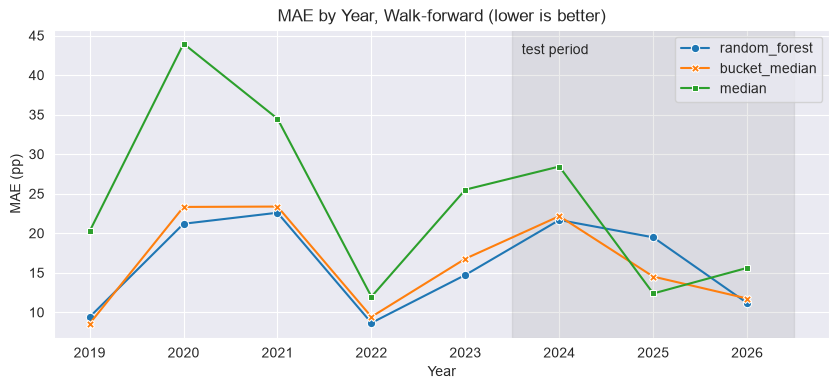

,random_forest,bucket_median,median
year,,,
2019,9.40,8.56,20.24
2020,21.19,23.32,43.97
2021,22.59,23.37,34.48
2022,8.66,9.42,11.97
2023,14.72,16.78,25.51
2024,21.67,22.16,28.43
2025,19.48,14.51,12.38
2026,11.17,11.74,15.61


In [20]:
# average miss per year for the forest and the two baselines
err_by_year = pd.DataFrame({m: (wf[m] - wf[target]).abs().groupby(wf["year"]).mean()
                            for m in ["random_forest", "bucket_median", "median"]})

plt.figure(figsize=(10, 4))
sns.lineplot(data=err_by_year, markers=True, dashes=False)
# grey shade = test years
plt.axvspan(2023.5, 2026.5, color="grey", alpha=0.15)
plt.text(2023.6, err_by_year.values.max(), "test period", va="top")
plt.title("MAE by Year, Walk-forward (lower is better)")
plt.xlabel("Year")
plt.ylabel("MAE (pp)")
plt.savefig(fig_dir + "07_error_by_year.png", dpi=120, bbox_inches="tight")
plt.show()
err_by_year

**Results (walk-forward):**

| Model | MAE 2019-23 | MAE 2024-26 | Spearman 2024-26 |
|---|---|---|---|
| **Random Forest** | **16.13** | 19.52 | **0.71** |
| LightGBM | 16.23 | 20.92 | 0.68 |
| Bucket median | 17.27 | **17.26** | 0.67 |
| Ridge | 18.69 | 20.08 | 0.65 |
| Median baseline | 26.70 | 19.06 | -0.17 |

**Point model: Random Forest** - lowest MAE on 2019-2023.

**Observations:**
- on 2024-2026 it **ranks** IPOs best of all models (Spearman **0.71**)
- but its absolute error is higher than the bucket median, mostly because of 2025, when everything listed lower
  than history suggested
- predicting the exact gain in a shifting market is hard, but **ordering IPOs from best to worst** works - and
  that's what an apply / skip decision needs. Notebook 5 tests that directly.

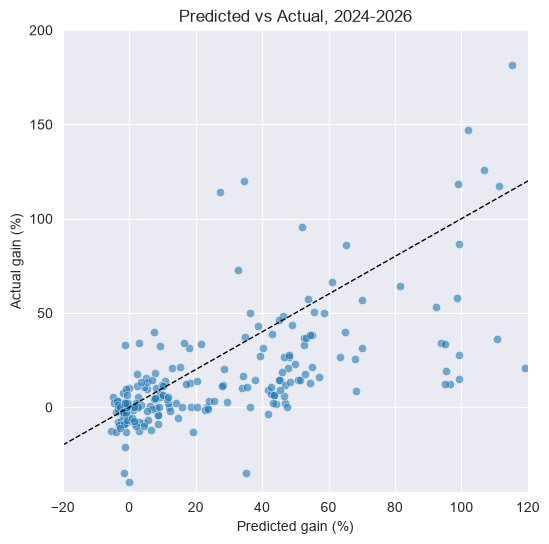

In [21]:
t = wf[wf["year"] >= 2024]

# each dot = one IPO, on the dashed line = perfect guess
plt.figure(figsize=(6, 6))
sns.scatterplot(x=t["random_forest"], y=t[target], alpha=0.6)
plt.plot([-45, 200], [-45, 200], "k--", lw=1)
plt.xlim(-20, 120)
plt.ylim(-45, 200)
plt.title("Predicted vs Actual, 2024-2026")
plt.xlabel("Predicted gain (%)")
plt.ylabel("Actual gain (%)")
plt.savefig(fig_dir + "08_pred_vs_actual.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 7: Predicting a Range (80%)

**What we do:** LightGBM with quantile loss for the 10th, 50th and 90th percentile, same walk-forward.
Quantiles trained separately can cross, so they are sorted.

**Why we do it:** With this much noise a single number isn't enough - an investor should also see the bear and
bull case.

In [22]:
# range instead of one number: 3 lightgbm models -> low (10th percentile), middle (50th), high (90th)
# same tuned settings as the lightgbm above, only the objective changes to "quantile"
q_params = {k: v for k, v in best["lightgbm"]["params"].items() if k != "objective"}
q_cols = feature_sets[best["lightgbm"]["data"]["features"]]


def fit_quantiles(tr):
    return [LGBMRegressor(learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42,
                          verbose=-1, objective="quantile", alpha=q, **q_params).fit(tr[q_cols], tr[target])
            for q in (0.1, 0.5, 0.9)]


# same quarterly walk-forward as above
d = df.sort_values("listing_date")
rows = d[wf_mask.reindex(d.index)]
parts = []
for q, chunk in rows.groupby(rows["listing_date"].dt.to_period("Q")):
    models = fit_quantiles(d[d["listing_date"] < q.start_time - lag])
    # sort each row so low <= middle <= high always (the 3 models can cross)
    p = np.sort(np.column_stack([m.predict(chunk[q_cols]) for m in models]), axis=1)
    parts.append(pd.DataFrame(p, index=chunk.index, columns=["p10", "p50", "p90"]))
wf = wf.join(pd.concat(parts))

# % of IPOs whose real gain fell inside p10..p90 (should be 80%, comes out lower)
inside = (wf[target] >= wf["p10"]) & (wf[target] <= wf["p90"])
inside.groupby(wf["year"] >= 2024).mean()

year
False   0.67
True    0.56
dtype: float64

**Observation:** Only **67%** (2019-23) and **56%** (2024-26) of actual gains fall inside the 10-90 range
instead of 80% - the quantile models are overconfident.

**Fix - rolling conformal calibration:**
1. for the last 60 IPOs known at the time, measure how far the actual gain fell outside its range
   (negative if inside)
2. take the 80% quantile of those distances (the margin)
3. widen the new IPO's range by that margin on both sides (needs at least 20 past IPOs)

**Result:** coverage **78%** (2019-23) and **79%** (2024-26) - close to the 80% target.

In [23]:
# rolling conformal fix: make the range wider by how much the recent ranges missed
dates = wf["listing_date"].to_numpy()
y = wf[target].to_numpy(dtype=float)
lo, hi = wf["p10"].to_numpy(dtype=float), wf["p90"].to_numpy(dtype=float)
# how far the real gain fell outside the range (negative = it was inside)
miss = np.maximum(lo - y, y - hi)

low, high = lo.copy(), hi.copy()
for i in range(len(wf)):
    # only IPOs whose result was known 7+ days before this one
    known = np.where(dates < dates[i] - np.timedelta64(7, "D"))[0]
    # the last 60 of them
    recent = known[np.argsort(dates[known], kind="stable")][-60:]
    # too few results to learn from -> keep the raw range
    if len(recent) < 20:
        continue
    n = len(recent)
    # margin = the miss that 80% of recent IPOs stayed under ((n + 1) / n is the small-sample correction)
    margin = np.quantile(miss[recent], min(1.0, np.ceil((n + 1) * 0.8) / n))
    # widen both ends by the margin
    low[i], high[i] = lo[i] - margin, hi[i] + margin

wf["low"], wf["high"] = low, high

In [24]:
# pinball loss = score for a quantile prediction (lower is better)
def pinball(y, p, q):
    diff = np.asarray(y, float) - np.asarray(p, float)
    return float(np.mean(np.maximum(q * diff, (q - 1) * diff)))


# coverage and width of the range, before (raw) and after the conformal fix
rng_rows = []
for period, sel in [("2019-2023", wf["year"] < 2024), ("2024-2026", wf["year"] >= 2024)]:
    part = wf[sel]
    yy = part[target]
    rng_rows.append({"period": period,
                     "raw_coverage": float(((yy >= part["p10"]) & (yy <= part["p90"])).mean()),
                     "raw_width": float(np.mean(part["p90"] - part["p10"])),
                     "coverage": float(((yy >= part["low"]) & (yy <= part["high"])).mean()),
                     "width": float(np.mean(part["high"] - part["low"])),
                     "pinball_p50": pinball(yy, part["p50"], 0.5)})
ranges = pd.DataFrame(rng_rows)
ranges.to_csv("../data/processed/range_results.csv", index=False)
ranges

,period,raw_coverage,raw_width,coverage,width,pinball_p50
0,2019-2023,0.67,36.73,0.78,47.67,8.40
1,2024-2026,0.56,41.63,0.79,56.84,9.02


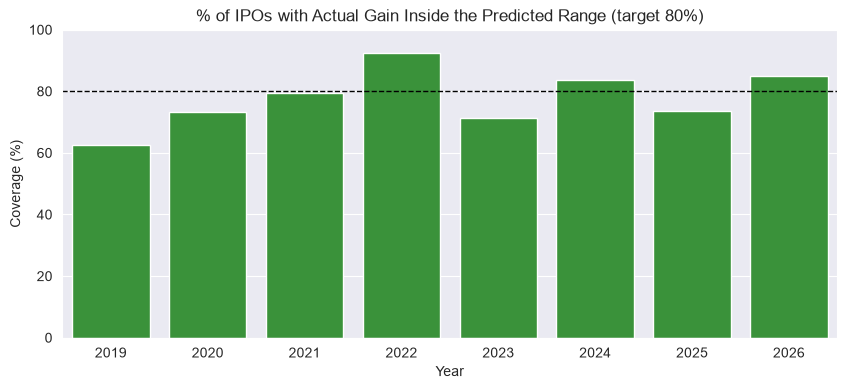

In [25]:
# coverage per year after the fix, dashed line = 80% target
cover = (((wf[target] >= wf["low"]) & (wf[target] <= wf["high"])).groupby(wf["year"]).mean() * 100).reset_index()
cover.columns = ["year", "coverage"]

plt.figure(figsize=(10, 4))
sns.barplot(data=cover, x="year", y="coverage", color="tab:green")
plt.axhline(80, color="black", ls="--", lw=1)
plt.ylim(0, 100)
plt.title("% of IPOs with Actual Gain Inside the Predicted Range (target 80%)")
plt.xlabel("Year")
plt.ylabel("Coverage (%)")
plt.savefig(fig_dir + "09_range_coverage.png", dpi=120, bbox_inches="tight")
plt.show()

In [26]:
# all walk-forward predictions + ranges -> used by the backtest notebook
wf.to_csv("../data/processed/wf_predictions.csv", index=False)

## Step 8: Feature Importance

**What we do:** Refit the Random Forest on all IPOs, then look at `feature_importances_` and SHAP values.

**Why we do it:** To understand what the model is using - and to explain every prediction in the app. SHAP also
shows the direction (does a feature push the prediction up or down?).

In [27]:
# final forest on all IPOs, only to look at what it uses
rf = train("random_forest", best["random_forest"]["params"], best["random_forest"]["data"], df)

# rf[-1] = the forest inside the pipeline (last step)
imp_df = pd.DataFrame({
    "col_name": base_features,
    "col_imp": rf[-1].feature_importances_
})
imp_df.sort_values(by="col_imp", ascending=False)

,col_name,col_imp
3,log_sub_total,0.33
0,log_sub_qib,0.19
1,log_sub_hni,0.13
2,log_sub_rii,0.10
5,log_issue_size,0.04
8,nifty_ret_3m,0.04
4,qib_to_rii,0.04
12,recent_ipo_count,0.03
11,recent_ipo_mean_gain,0.03
9,nifty_vs_200dma,0.02


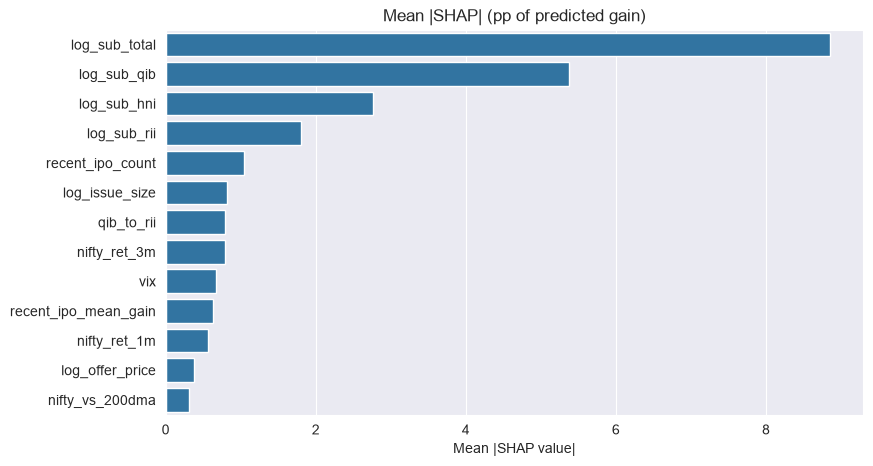

,feature,mean_abs_shap
3,log_sub_total,8.85
0,log_sub_qib,5.38
1,log_sub_hni,2.76
2,log_sub_rii,1.81
12,recent_ipo_count,1.05
5,log_issue_size,0.82
4,qib_to_rii,0.80
8,nifty_ret_3m,0.79
10,vix,0.67
11,recent_ipo_mean_gain,0.63


In [28]:
# rf[:-1] = the imputer, so X is the same filled data the forest sees
X = pd.DataFrame(rf[:-1].transform(df[base_features]), columns=base_features)
# shap value = how many % points this feature added to / took away from this IPO's prediction
sv = shap.TreeExplainer(rf[-1])(X)

# average size of the push of each feature (ignoring up or down)
shap_imp = pd.DataFrame({"feature": base_features, "mean_abs_shap": np.abs(sv.values).mean(axis=0)})
shap_imp = shap_imp.sort_values(by="mean_abs_shap", ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=shap_imp, x="mean_abs_shap", y="feature", color="tab:blue")
plt.title("Mean |SHAP| (pp of predicted gain)")
plt.xlabel("Mean |SHAP value|")
plt.ylabel("")
plt.savefig(fig_dir + "10_shap_importance.png", dpi=120, bbox_inches="tight")
plt.show()
shap_imp

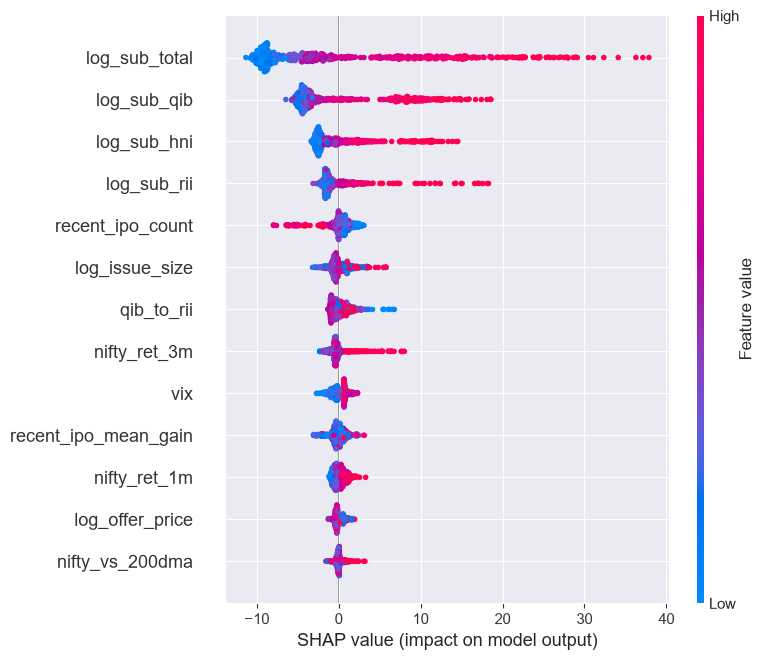

In [29]:
# one dot per IPO per feature: right = pushed the guess up, left = down, colour = feature value (red high, blue low)
shap.summary_plot(sv.values, X, show=False)
plt.savefig(fig_dir + "11_shap_beeswarm.png", dpi=120, bbox_inches="tight")
plt.show()

**Observations:**
- total and QIB subscription drive most of the prediction, then HNI and retail
- market features (recent IPO count, NIFTY 3m return, VIX) only adjust it by about **1 pp** on average
- high subscription pushes the prediction up, as expected

## Summary

| Step | Result |
|---|---|
| Tuning (2010-2023, year folds) | Random Forest best: CV MAE 16.03 vs 17.21 for the bucket median |
| Train vs valid | untuned trees fit training data almost perfectly; limiting depth shrank the gap |
| Frozen model on 2024-26 | failed - subscription inflation |
| Walk-forward on 2024-26 | best ranking (Spearman 0.71), MAE 19.5 vs 17.3 for the bucket median |
| 80% range | 79% coverage on 2024-26 after conformal calibration |

The app uses the same settings refit on all IPOs - `python -m src.models.evaluate` saves that model to
`models/deploy.pkl`.

**Next notebook:** `05_backtest.ipynb`